# 01 - UCI Heart Disease: data exploration

**MedIntel AI | Research prototype**

Explore the official **processed Cleveland subset** of UCI Heart Disease:
303 records, 13 features, and the original diagnosis field, `num`.
The other UCI cohorts are outside this notebook's scope.

We will inspect the structure, missingness, summary statistics, and distributions.
All records and original diagnosis codes are retained. No model is trained.

## Sources and attribution

- [UCI dataset page](https://archive.ics.uci.edu/dataset/45/heart+disease)
- [Official processed Cleveland file](https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data)
- [Original variable documentation](https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/heart-disease.names)
- Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989).
  *Heart Disease* [Dataset]. UCI Machine Learning Repository.
  [DOI: 10.24432/C52P4X](https://doi.org/10.24432/C52P4X).
  Cleveland data collection: Robert Detrano, Cleveland Clinic Foundation.
- UCI lists the dataset under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

## How to run

Install `requirements.txt` in the project's virtual environment, open this notebook
in VS Code or Jupyter, select that Python environment, and run all cells in order.
Start Jupyter from the project root or `notebooks/`. The first run needs internet
access to UCI; later runs reuse the unmodified local file in `data/raw/`.
No extra dependencies are needed.

## 1. Import tools and set plotting defaults

**Code explanation:** `Path` locates project files, `urlopen` downloads the official
source, and `sha256` fingerprints the local bytes for reproducibility. pandas
handles tables; matplotlib and seaborn draw plots. `display` renders tables in
Jupyter. The style settings make plots readable without changing any data.

In [1]:
from hashlib import sha256
from pathlib import Path
from urllib.error import URLError
from urllib.request import urlopen

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 20)

## 2. Download once and load the data

**Code explanation:** Search the working directory and its parents for this
project's `requirements.txt` and `data/raw/`. Download only when the cached file
does not exist, with a 30-second timeout and a helpful error if UCI is unreachable.
The file has **no header**, so supply its 14 column names in the documented order.
`na_values=["?"]` converts the missing markers in this processed file into pandas
missing values. Unlike the full original records, this file uses question marks.
The shape check catches an unexpected source version. Printing the URL, local path,
and SHA-256 identifies exactly which file was analyzed.

Although UCI names this file `processed.cleveland.data`, it belongs in our
`data/raw/` because it is the unmodified input to this project. That folder is
excluded from Git.

In [2]:
DATA_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)
COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num",
]

working_directory = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        folder for folder in [working_directory, *working_directory.parents]
        if (folder / "requirements.txt").is_file()
        and (folder / "data" / "raw").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter from MedIntel-AI or its notebooks folder.")

raw_path = PROJECT_ROOT / "data" / "raw" / "processed.cleveland.data"
if not raw_path.exists():
    try:
        with urlopen(DATA_URL, timeout=30) as response:
            source_bytes = response.read()
    except (URLError, TimeoutError) as error:
        raise RuntimeError(
            "Could not download the official UCI file. Check your connection, "
            "or save the file from DATA_URL to data/raw/processed.cleveland.data "
            "and rerun this cell."
        ) from error
    raw_path.write_bytes(source_bytes)

df = pd.read_csv(raw_path, header=None, names=COLUMNS, na_values=["?"])
if df.shape != (303, 14):
    raise ValueError(f"Expected the Cleveland file to have shape (303, 14); got {df.shape}.")

print(f"Source: {DATA_URL}")
print(f"Local file: {raw_path.relative_to(PROJECT_ROOT)}")
print(f"SHA-256: {sha256(raw_path.read_bytes()).hexdigest()}")
print(f"Loaded {df.shape[0]} rows and {df.shape[1]} columns.")

Source: https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data
Local file: data\raw\processed.cleveland.data
SHA-256: a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8
Loaded 303 rows and 14 columns.


## 3. Read the column definitions

These definitions follow the [UCI variable documentation](https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/heart-disease.names).
Numeric storage does not make a category a continuous measurement.

| Column | Meaning / original codes |
| --- | --- |
| `age` | Age (years) |
| `sex` | Recorded sex: 0 female, 1 male |
| `cp` | Chest pain: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| `trestbps` | Resting blood pressure (mm Hg) |
| `chol` | Serum cholesterol (mg/dL) |
| `fbs` | Fasting glucose above 120 mg/dL: 0 false, 1 true |
| `restecg` | Resting ECG: 0 normal, 1 ST-T abnormality, 2 probable/definite LV hypertrophy |
| `thalach` | Maximum heart rate achieved |
| `exang` | Exercise angina: 0 no, 1 yes |
| `oldpeak` | Exercise-related ST depression relative to rest |
| `slope` | Peak exercise ST slope: 1 upward, 2 flat, 3 downward |
| `ca` | Major vessels visualized by fluoroscopy (0-3) |
| `thal` | Test result: 3 normal, 6 fixed defect, 7 reversible defect |
| `num` | Diagnosis code: 0 absence, 1-4 presence of disease |

`thal` describes a test result; it is not a thalassemia diagnosis.

## 4. Inspect records, columns, and types

**Code explanation:** Show the first and last five records to inspect both ends
of the file. Print the ordered column names and call `info()` to report storage
types and non-missing counts. The column profile adds distinct-value counts;
`dropna=False` includes missingness as a distinct state for this inspection.

In [3]:
print("First five records:")
display(df.head())
print("Last five records:")
display(df.tail())
print("Column names:", df.columns.tolist())
df.info()

column_profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "distinct_including_missing": df.nunique(dropna=False),
})
display(column_profile)

First five records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Last five records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


Column names: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,dtype,non_missing,distinct_including_missing
age,float64,303,41
sex,float64,303,2
cp,float64,303,4
trestbps,float64,303,50
chol,float64,303,152
fbs,float64,303,2
restecg,float64,303,3
thalach,float64,303,91
exang,float64,303,2
oldpeak,float64,303,40


## 5. Identify missing values and duplicate records

**Code explanation:** `isna()` finds missing cells. Summing by column gives
counts, and averaging gives proportions, converted to percentages. Show every
affected record so missingness is visible in context. `duplicated()` counts
exact repeated rows. No records are dropped and no values are imputed.

The official processed Cleveland file should show four missing `ca` values
and two missing `thal` values. The calculations below verify the local copy.

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)
display(missing_summary)

rows_with_missing = df.isna().any(axis=1)
print(f"Missing cells: {int(df.isna().sum().sum())}")
print(f"Rows with at least one missing value: {int(rows_with_missing.sum())}")
print(f"Exact duplicate rows (after the first occurrence): {int(df.duplicated().sum())}")
display(df.loc[rows_with_missing])

,missing_count,missing_percent
ca,4,1.32
thal,2,0.66
cp,0,0.00
trestbps,0,0.00
age,0,0.00
sex,0,0.00
fbs,0,0.00
chol,0,0.00
restecg,0,0.00
thalach,0,0.00


Missing cells: 6
Rows with at least one missing value: 6
Exact duplicate rows (after the first occurrence): 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


## 6. Visualize missingness

**Code explanation:** Draw a horizontal bar for each column that contains missing
values and annotate its count. This makes the concentration of missingness easy
to compare. If a source has no missing cells, print a message instead of drawing
an empty plot. This chart reports frequency, not the cause of missingness.

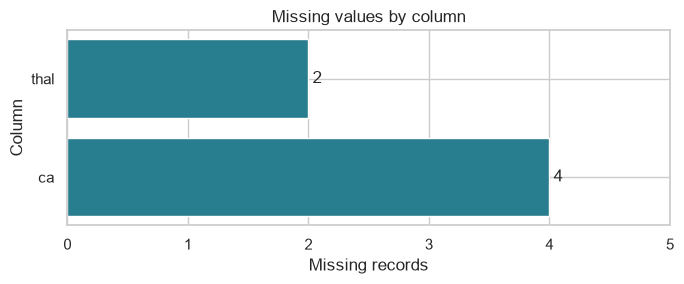

In [5]:
missing_columns = missing_summary.loc[missing_summary["missing_count"] > 0]
if missing_columns.empty:
    print("No missing values found.")
else:
    fig, ax = plt.subplots(figsize=(7, 3))
    bars = ax.barh(missing_columns.index, missing_columns["missing_count"], color="#287D8E")
    ax.bar_label(bars, padding=3, fmt="%.0f")
    ax.set(title="Missing values by column", xlabel="Missing records", ylabel="Column")
    ax.set_xlim(0, missing_columns["missing_count"].max() + 1)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

## 7. Summarize measurements and check category codes

**Code explanation:** Define five measurement columns for descriptive statistics
and histograms. Keep coded categories and the discrete vessel count separate.
`describe().T` shows counts, averages, spread, and quartiles for measurements;
counts exclude missing values. For coded fields, compare observed non-missing
values against the documented codes. This can expose a recoded or incorrect file
without silently replacing unexpected values. `num` remains the original outcome.

In [6]:
MEASUREMENTS = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORY_CODES = {
    "sex": [0, 1],
    "cp": [1, 2, 3, 4],
    "fbs": [0, 1],
    "restecg": [0, 1, 2],
    "exang": [0, 1],
    "slope": [1, 2, 3],
    "ca": [0, 1, 2, 3],
    "thal": [3, 6, 7],
    "num": [0, 1, 2, 3, 4],
}
MEASUREMENT_LABELS = {
    "age": "Age (years)",
    "trestbps": "Resting blood pressure (mm Hg)",
    "chol": "Serum cholesterol (mg/dL)",
    "thalach": "Maximum heart rate achieved",
    "oldpeak": "ST depression relative to rest",
}

display(df[MEASUREMENTS].describe().T.round(2))
category_checks = []
for column, expected_codes in CATEGORY_CODES.items():
    observed = sorted(df[column].dropna().unique().tolist())
    category_checks.append({
        "column": column,
        "observed_codes": observed,
        "unexpected_codes": sorted(set(observed) - set(expected_codes)),
        "missing_count": int(df[column].isna().sum()),
    })
display(pd.DataFrame(category_checks).set_index("column"))

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


,observed_codes,unexpected_codes,missing_count
column,,,
sex,"[0.0, 1.0]",[],0
cp,"[1.0, 2.0, 3.0, 4.0]",[],0
fbs,"[0.0, 1.0]",[],0
restecg,"[0.0, 1.0, 2.0]",[],0
exang,"[0.0, 1.0]",[],0
slope,"[1.0, 2.0, 3.0]",[],0
ca,"[0.0, 1.0, 2.0, 3.0]",[],4
thal,"[3.0, 6.0, 7.0]",[],2
num,"[0, 1, 2, 3, 4]",[],0


## 8. Visualize measurement distributions

**Code explanation:** Plot one histogram per measurement using 20 bins. Each
plot has its own units and scale. Histograms reveal concentration, skew, and
extreme observations; the dashed line marks the median. `dropna()` omits missing
values only from the plot input and does not modify `df`. The unused sixth panel
is hidden. Extreme observations are retained for later investigation.

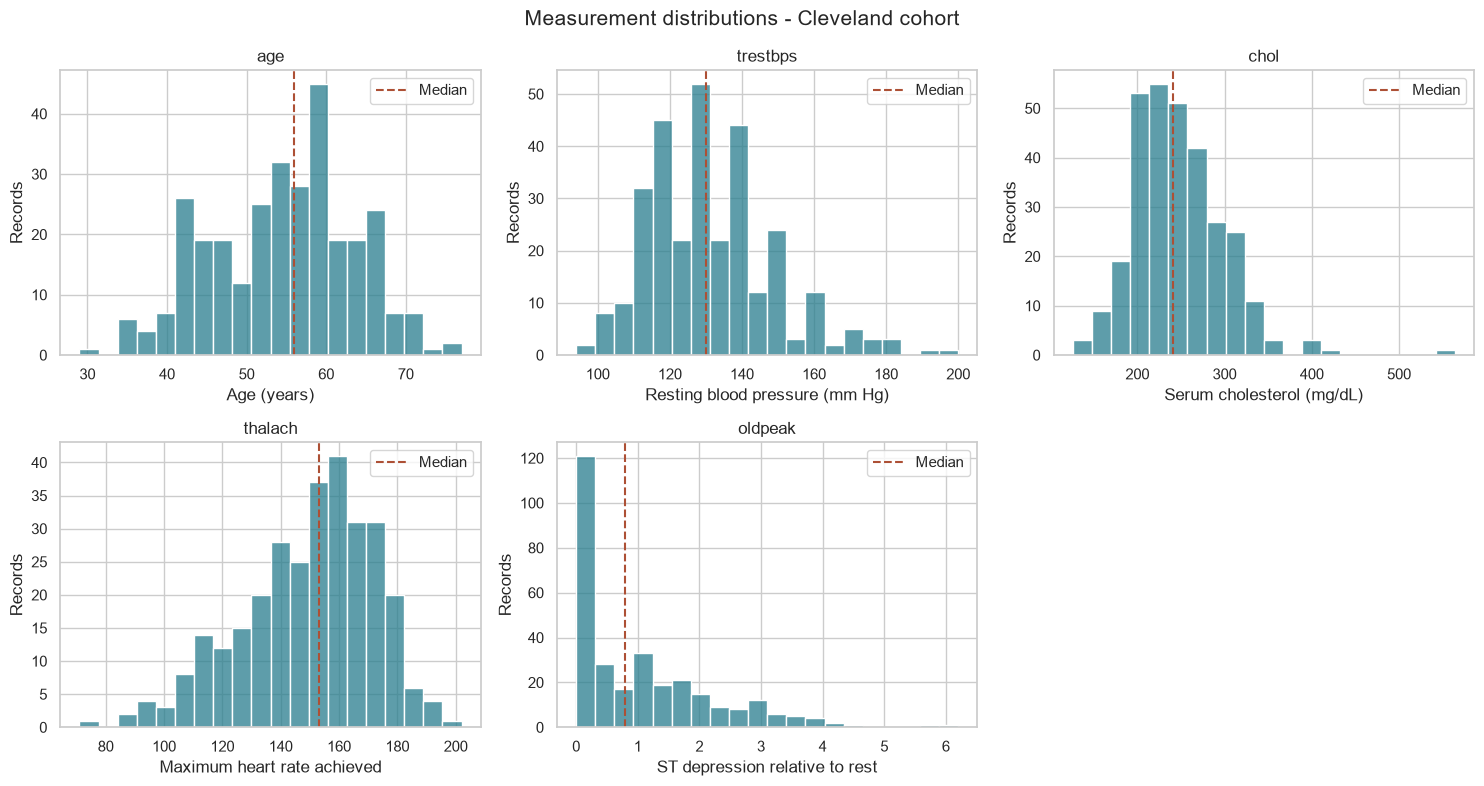

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, MEASUREMENTS):
    values = df[column].dropna()
    sns.histplot(x=values, bins=20, ax=ax, color="#287D8E")
    ax.axvline(values.median(), color="#AD5035", linestyle="--", label="Median")
    ax.set(title=column, xlabel=MEASUREMENT_LABELS[column], ylabel="Records")
    ax.legend()
axes.flat[-1].set_visible(False)
fig.suptitle("Measurement distributions - Cleveland cohort", fontsize=15)
fig.tight_layout()
plt.show()

## 9. Visualize categorical and discrete distributions

**Code explanation:** Count each documented code for the eight non-outcome
coded/discrete fields. Reindexing includes valid codes with zero observations.
Add a separate `Missing` bar when needed so its records remain visible.
Annotate every bar with its record count. Keep UCI's original codes on the axes;
use the dictionary above to interpret them. The vessel count `ca` is discrete,
so it is also shown as a count chart rather than a continuous histogram.

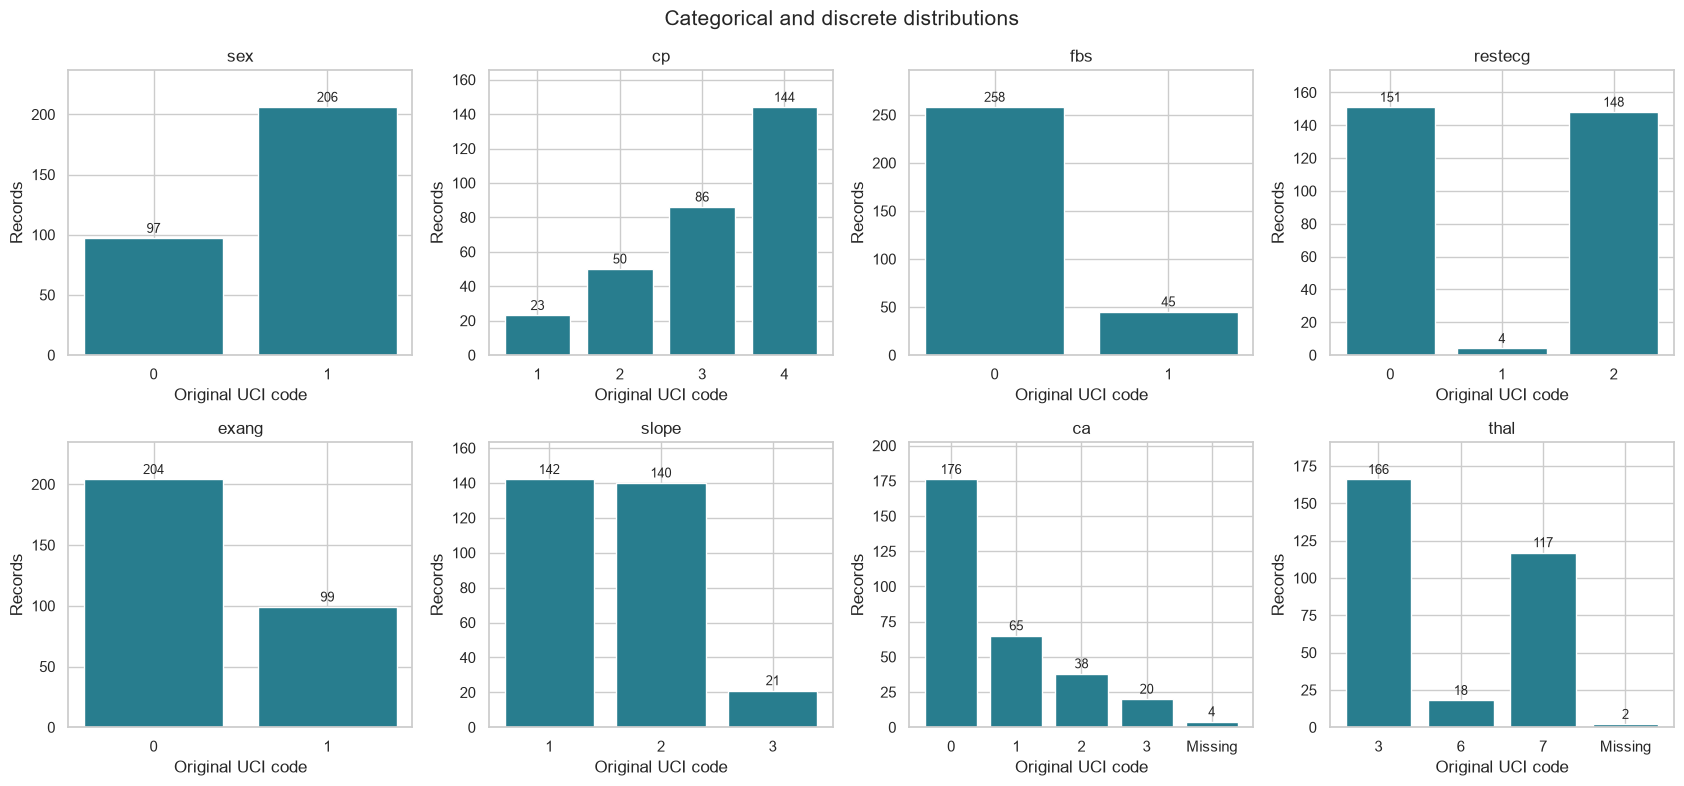

In [8]:
categorical_features = [column for column in CATEGORY_CODES if column != "num"]
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, column in zip(axes.flat, categorical_features):
    counts = df[column].value_counts().reindex(CATEGORY_CODES[column], fill_value=0)
    labels = [str(value) for value in CATEGORY_CODES[column]]
    heights = counts.tolist()
    missing_count = int(df[column].isna().sum())
    if missing_count:
        labels.append("Missing")
        heights.append(missing_count)
    bars = ax.bar(labels, heights, color="#287D8E")
    ax.bar_label(bars, padding=2, fmt="%.0f", fontsize=9)
    ax.set(title=column, xlabel="Original UCI code", ylabel="Records")
    ax.set_ylim(0, max(heights) * 1.15)
fig.suptitle("Categorical and discrete distributions", fontsize=15)
fig.tight_layout()
plt.show()

## 10. Examine the diagnosis distribution

**Code explanation:** Count all five original `num` codes, then create a separate
descriptive view that groups 1-4 as disease present and 0 as disease absent.
This follows UCI's documented interpretation and does not overwrite `num`.
The check rejects missing or unexpected diagnosis codes before grouping them.
Show counts and percentages for both views, then plot their counts. The binary
view is a summary of recorded diagnoses, not a predicted probability or an
estimate of population prevalence.

Original diagnosis codes


,count,percent
num,,
0,164,54.13
1,55,18.15
2,36,11.88
3,35,11.55
4,13,4.29


Binary summary


,count,percent
num,,
Absent (0),164,54.13
Present (1-4),139,45.87


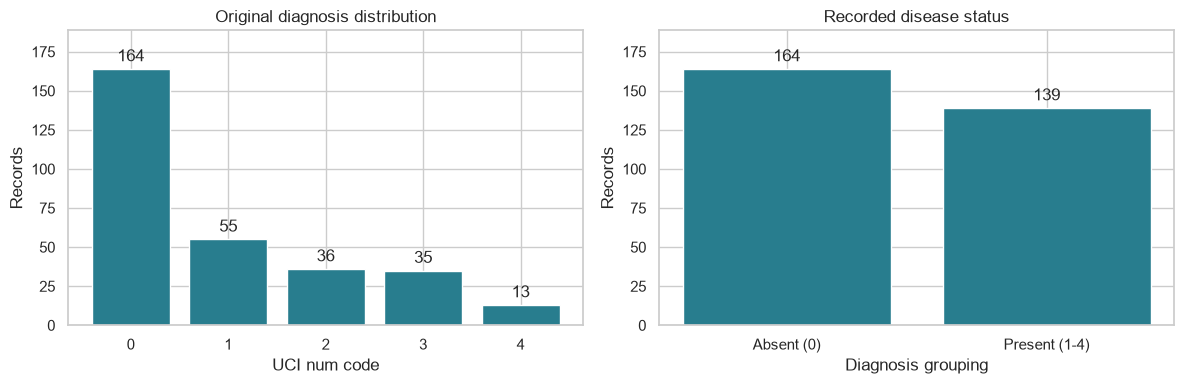

In [9]:
if df["num"].isna().any() or not df["num"].isin(CATEGORY_CODES["num"]).all():
    raise ValueError("Diagnosis codes must be non-missing integers from 0 through 4.")

diagnosis_counts = df["num"].value_counts().reindex(range(5), fill_value=0)
disease_status = df["num"].gt(0).map({False: "Absent (0)", True: "Present (1-4)"})
status_order = ["Absent (0)", "Present (1-4)"]
status_counts = disease_status.value_counts().reindex(status_order, fill_value=0)

for label, counts in [("Original diagnosis codes", diagnosis_counts), ("Binary summary", status_counts)]:
    print(label)
    display(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, title, xlabel in [
    (axes[0], diagnosis_counts, "Original diagnosis distribution", "UCI num code"),
    (axes[1], status_counts, "Recorded disease status", "Diagnosis grouping"),
]:
    bars = ax.bar(counts.index.astype(str), counts.values, color="#287D8E")
    ax.bar_label(bars, padding=3, fmt="%.0f")
    ax.set(title=title, xlabel=xlabel, ylabel="Records", ylim=(0, counts.max() * 1.15))
fig.tight_layout()
plt.show()

## 11. Compare measurements across recorded diagnoses

**Code explanation:** Add the descriptive disease-status labels to a temporary
plotting copy, then draw one boxplot per measurement for the two groups. A box
spans the middle 50% of observations and its line marks the median; whiskers and
points show spread and potential extremes under the usual 1.5-IQR convention.
These are exploratory comparisons, with no significance tests or causal claims.
This cell leaves the original dataframe unchanged.

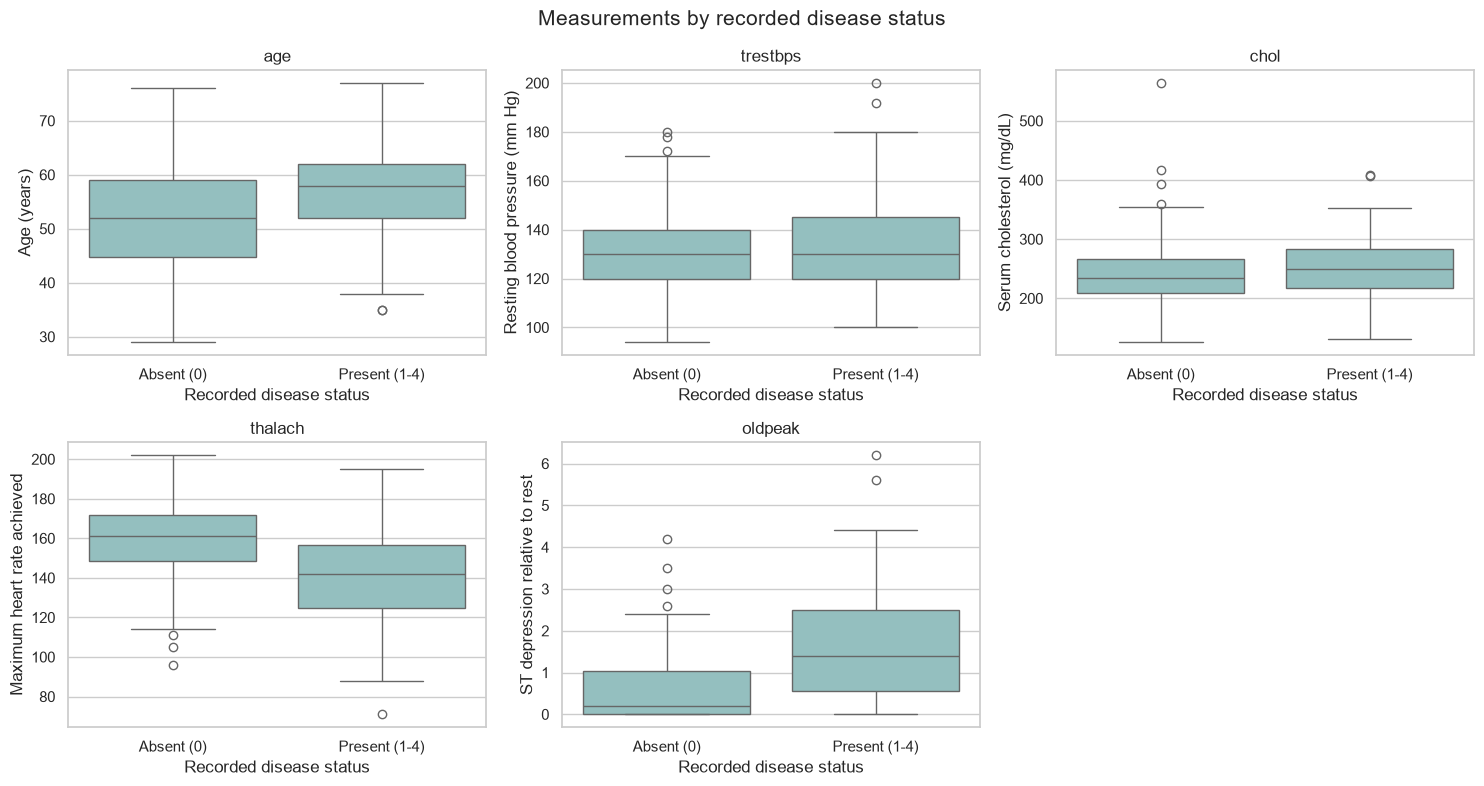

In [10]:
plot_data = df.assign(disease_status=disease_status)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, MEASUREMENTS):
    sns.boxplot(
        data=plot_data, x="disease_status", y=column,
        order=status_order, color="#8DC6C6", ax=ax,
    )
    ax.set(title=column, xlabel="Recorded disease status", ylabel=MEASUREMENT_LABELS[column])
axes.flat[-1].set_visible(False)
fig.suptitle("Measurements by recorded disease status", fontsize=15)
fig.tight_layout()
plt.show()

## 12. Summarize the observed data quality

**Code explanation:** Calculate a compact audit from the loaded dataframe so the
findings stay tied to the actual local file. The summary reports dimensions,
missingness, duplicate records, and the two diagnosis groups. This is descriptive
reporting only; nothing is fitted, transformed for training, or exported.

In [11]:
audit = pd.Series({
    "Records": len(df),
    "Original columns (including diagnosis)": len(df.columns),
    "Missing cells": int(df.isna().sum().sum()),
    "Records with missing values": int(df.isna().any(axis=1).sum()),
    "Exact duplicate rows after first occurrence": int(df.duplicated().sum()),
    "Disease absent (num = 0)": int(df["num"].eq(0).sum()),
    "Disease present (num = 1-4)": int(df["num"].gt(0).sum()),
}, name="Observed value")
display(audit.to_frame())

,Observed value
Records,303
Original columns (including diagnosis),14
Missing cells,6
Records with missing values,6
Exact duplicate rows after first occurrence,0
Disease absent (num = 0),164
Disease present (num = 1-4),139


## Findings and interpretation

For the official file verified in this notebook:

- There are **303 records and 14 original columns**, including the diagnosis.
- **Six records have missing values**: four in `ca` and two in `thal`.
  These records remain in the data, and missing categories are shown explicitly.
- Recorded diagnoses are **164 absent** and **139 present**; the original five
  codes are retained alongside the separate binary summary.
- Measurement histograms and boxplots expose asymmetric distributions and
  extreme observations, including in cholesterol and ST depression. Investigate
  such records before deciding whether any correction is appropriate.
- The cohort contains more records coded male than female. This and its
  historical, single-cohort sampling limit how broadly findings can be applied.

All counts above can be checked against the executed tables. Group differences
describe this sample; they do not establish causality or validate a clinical tool.
The diagnosis records existing disease status, not future disease onset.

## Questions for later work

Document a missing-value strategy, review unusual values and cohort coverage,
and define the research outcome before any modeling. Any future learned
preprocessing must be fitted on training data only after a suitable split.
This notebook ends with exploration: no imputation, scaling, encoding for
training, model fitting, or frontend implementation is performed.